In [1]:
import requests

# Open-Meteo historical weather API (free, no key needed)
url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": 39.46,
    "longitude": -0.4275,
    "start_date": "2026-10-23",
    "end_date": "2026-10-28",
    "hourly": "precipitation,temperature_2m,relative_humidity_2m,wind_speed_10m",
    "timezone": "Europe/Madrid",
}

response = requests.get(url, params=params, timeout=30)
data = response.json()
hourly = data["hourly"]

print("Variables:", list(hourly.keys()))
print("Number of hours:", len(hourly["time"]))

Variables: ['time', 'precipitation', 'temperature_2m', 'relative_humidity_2m', 'wind_speed_10m']
Number of hours: 144


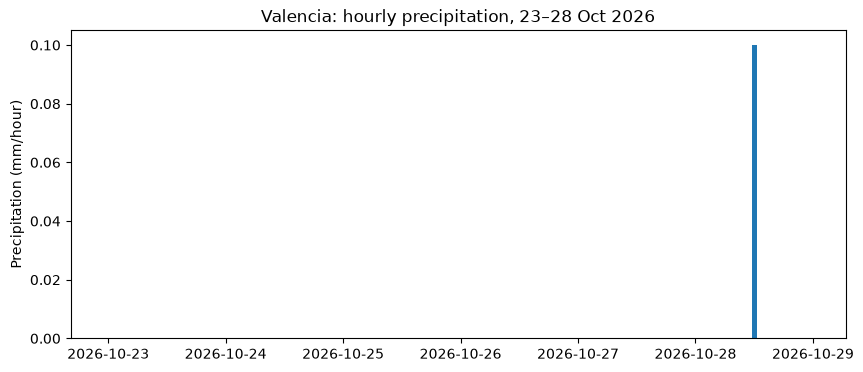

Total precipitation: 0.1 mm
Max in one hour: 0.1 mm


In [2]:
import matplotlib.pyplot as plt
from datetime import datetime

# Convert time strings ("2026-10-23T00:00") to real dates
times = [datetime.fromisoformat(t) for t in hourly["time"]]
rain = [p or 0 for p in hourly["precipitation"]]   # replace missing values with 0

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(times, rain, width=0.04)                    # one bar per hour (0.04 day ≈ 1 hour)
ax.set_ylabel("Precipitation (mm/hour)")
ax.set_title("Valencia: hourly precipitation, 23–28 Oct 2026")
plt.show()

print("Total precipitation:", round(sum(rain), 1), "mm")
print("Max in one hour:", max(rain), "mm")

In [3]:
import json
import os
from collections import defaultdict

# Sum precipitation per day ("2026-10-23T05:00" -> "2026-10-23")
daily_rain = defaultdict(float)
for t, p in zip(hourly["time"], hourly["precipitation"]):
    daily_rain[t[:10]] += p or 0

output = {
    "zone": "valencia",
    "location": "Valencia, Spain",
    "latitude": params["latitude"],
    "longitude": params["longitude"],
    "start_date": params["start_date"],
    "end_date": params["end_date"],
    "source": "Open-Meteo Historical Weather API (archive-api.open-meteo.com)",
    "units": {"precipitation": "mm", "temperature_2m": "°C",
              "relative_humidity_2m": "%", "wind_speed_10m": "km/h"},
    "total_precipitation_mm": round(sum(daily_rain.values()), 1),
    "daily_precipitation_mm": {day: round(mm, 1) for day, mm in daily_rain.items()},
    "hourly": hourly,
}

out_dir = "../public/data/valencia"
os.makedirs(out_dir, exist_ok=True)
with open(f"{out_dir}/weather.json", "w") as f:
    json.dump(output, f, indent=1)

print("Saved:", f"{out_dir}/weather.json")
print("Daily precipitation:", output["daily_precipitation_mm"])

Saved: ../public/data/valencia/weather.json
Daily precipitation: {'2026-10-23': 0.0, '2026-10-24': 0.0, '2026-10-25': 0.0, '2026-10-26': 0.0, '2026-10-27': 0.0, '2026-10-28': 0.1}
